In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
def plot_normalized_cm(cm, class_names, title="Normalized CM"):
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8,6))
    plt.imshow(cm_norm)
    plt.title(title)
    plt.colorbar()

    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names, rotation=45)
    plt.yticks(ticks, class_names)

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, f"{cm_norm[i,j]:.4f}", ha='center', va='center')

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()
def load_and_merge(split_name):
    """Loads and merges data for a specific split (train, val, or test)."""
    trans_path = f"/content/drive/MyDrive/cicids2017/tran_{split_name}_predictions.csv"
    cnn_path = f"/content/drive/MyDrive/cicids2017/cnn_{split_name}_predictions.csv"

    trans_df = pd.read_csv(trans_path)
    cnn_df = pd.read_csv(cnn_path)


    # Merge on image_name and true_label
    merged_df = pd.merge(
    cnn_df,
    trans_df,
    on=["image_name", "true_label"]
)

    return merged_df

# Load the validation and test sets
train_df = load_and_merge("train")
val_df = load_and_merge("val")
feature_cols = []

for col in train_df.columns:
    if col.startswith("cnn_") or col.startswith("trans_"):
        if "pred" not in col:
            feature_cols.append(col)



# --- 1. Fix Label Encoding ---
le = LabelEncoder()
y_train = le.fit_transform(train_df['true_label'])
X_train = train_df[feature_cols]

# IMPORTANT: Use .transform() on the validation/test set, not fit_transform()
y_test = le.transform(val_df['true_label'])
X_test = val_df[feature_cols]

In [ ]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def compute_smoothed_weights(y, smooth_factor=0.15):
    # Count occurrences of each class
    classes, counts = np.unique(y, return_counts=True)
    total_samples = len(y)

    # Apply logarithmic smoothing
    # Ensure counts are not zero to avoid division by zero
    safe_counts = np.where(counts == 0, 1e-6, counts) # Use a small number instead of 0
    smoothed_weights_array = total_samples / (safe_counts ** smooth_factor)

    # Normalize so the minimum weight or average weight stays reasonable
    smoothed_weights_array /= np.mean(smoothed_weights_array)

    # Map class labels to their smoothed weights
    class_weight_dict = {cls: weight for cls, weight in zip(classes, smoothed_weights_array)}
    return class_weight_dict

class_names = sorted(val_df['true_label'].unique())
class_weight_dict = compute_smoothed_weights(y_train, smooth_factor=0.25)


Performing 2-fold cross-validation for LightGBM...

--- Fold 1/2 ---
Fold Accuracy: 0.9845


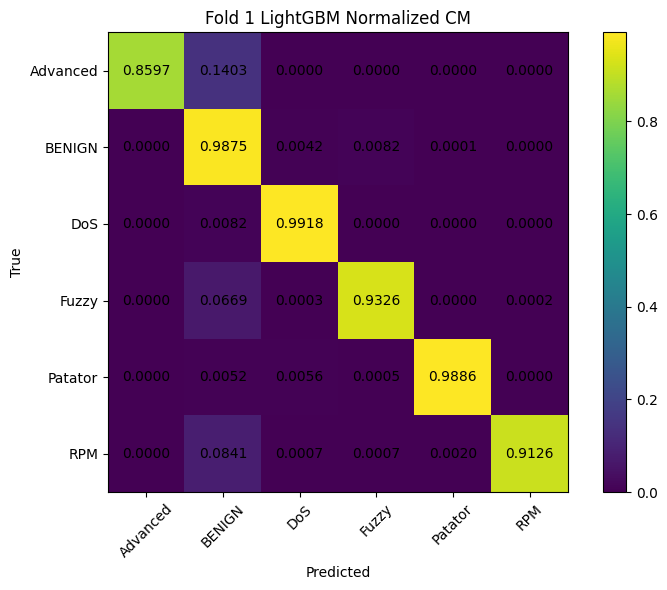


--- Fold 2/2 ---
Fold Accuracy: 0.9843


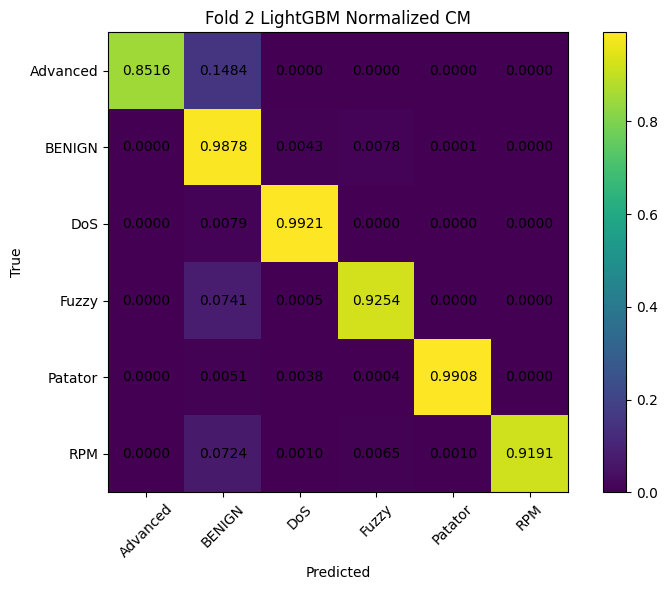


--- Cross-Validation Summary ---
Average Accuracy across 2 folds: 0.9844 (+/- 0.0001)


In [ ]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# Assuming lgbm_model and class_names are already defined from previous cells
# lgbm_model was defined in cell uI8wGjGxMkFo
# class_names was defined in cell -BYhPbh3vt-z and also used in uI8wGjGxMkFo
y_true_labels = le.inverse_transform(y_test)
class_names = sorted(val_df['true_label'].unique())
# Combine X_train and y_train for cross-validation
X_data = pd.concat([X_train, X_test])
y_data = np.concatenate([y_train, y_test])

# Initialize Stratified K-Fold Cross-Validation
n_splits = 2
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

print(f"Performing {n_splits}-fold cross-validation for LightGBM...")

reports = []
confusion_matrices = []
accuracies = []
sf=1
for fold, (train_index, test_index) in enumerate(skf.split(X_data, y_data)):

    print(f"\n--- Fold {fold + 1}/{n_splits} ---")
    X_train_fold, X_test_fold = X_data.iloc[train_index], X_data.iloc[test_index]
    y_train_fold, y_test_fold = y_data[train_index], y_data[test_index]
    class_weight_dict = compute_smoothed_weights(y_train_fold, smooth_factor=0.25)

    # Initialize a new LightGBM model for each fold to ensure independent training
    fold_lgbm_model = RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight=class_weight_dict,
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=3,
        max_features='log2',
        bootstrap=True
    )

    fold_lgbm_model.fit(X_train_fold, y_train_fold)
    y_pred_fold = fold_lgbm_model.predict(X_test_fold)

    # Evaluate the model for the current fold
    fold_accuracy = accuracy_score(y_test_fold, y_pred_fold)
    accuracies.append(fold_accuracy)

    print(f"Fold Accuracy: {fold_accuracy:.4f}")
    # Generate classification report for the fold
    report = classification_report(
        le.inverse_transform(y_test_fold),
        le.inverse_transform(y_pred_fold),
        target_names=class_names, # Use class_names for target_names
        output_dict=True
    )
    reports.append(report)

    # Generate confusion matrix for the fold
    cm_fold = confusion_matrix(le.inverse_transform(y_test_fold), le.inverse_transform(y_pred_fold))
    confusion_matrices.append(cm_fold)

    plot_normalized_cm(cm_fold, class_names, f"Fold {fold + 1} LightGBM Normalized CM")
    sf+=1

print("\n--- Cross-Validation Summary ---")
print(f"Average Accuracy across {n_splits} folds: {np.mean(accuracies):.4f} (+/- {np.std(accuracies):.4f})")

# You can further process 'reports' and 'confusion_matrices' to get average metrics
# For example, average F1-score for each class across all folds.



Calculating Permutation Importance (this may take a moment)...


/tmp/ipykernel_7144/3356892166.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


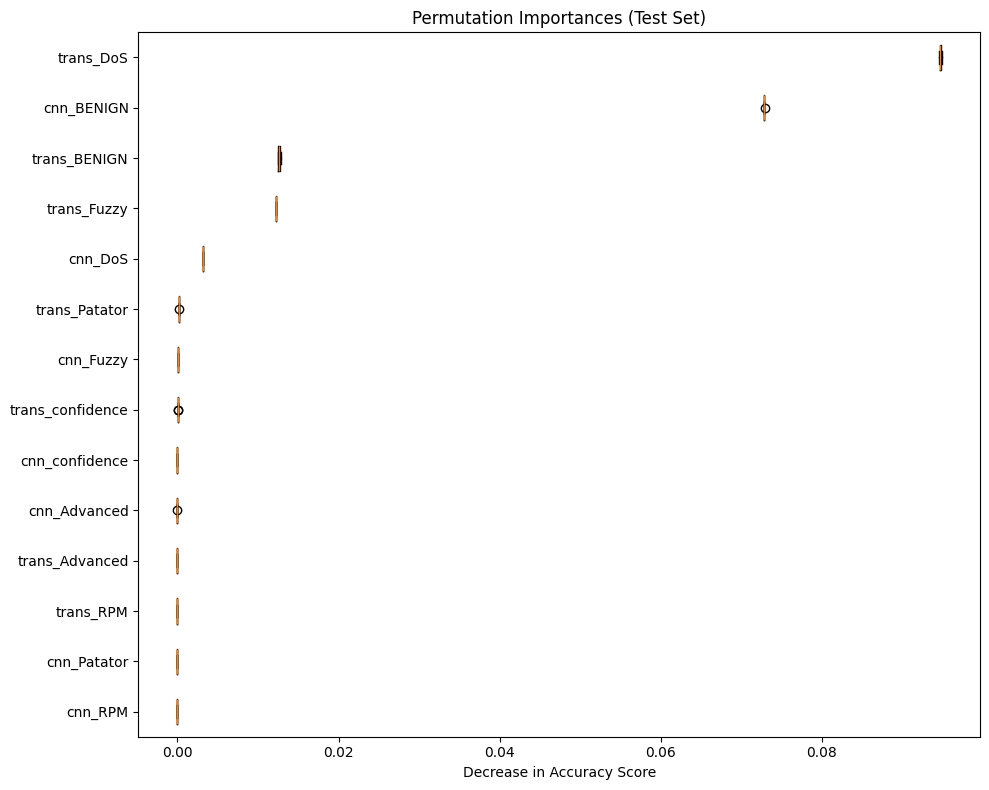


Feature Ranking:
trans_DoS: 0.0947 +/- 0.0001
cnn_BENIGN: 0.0729 +/- 0.0001
trans_BENIGN: 0.0126 +/- 0.0001
trans_Fuzzy: 0.0122 +/- 0.0000
cnn_DoS: 0.0031 +/- 0.0000
trans_Patator: 0.0002 +/- 0.0000
cnn_Fuzzy: 0.0001 +/- 0.0000
trans_confidence: 0.0000 +/- 0.0000
cnn_confidence: -0.0000 +/- 0.0000
cnn_Advanced: -0.0001 +/- 0.0000
trans_Advanced: -0.0001 +/- 0.0000
trans_RPM: -0.0001 +/- 0.0000
cnn_Patator: -0.0001 +/- 0.0000
cnn_RPM: -0.0001 +/- 0.0000


In [ ]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# We will use the Random Forest model from the previous cross-validation fold for this analysis
print("Calculating Permutation Importance (this may take a moment)...")

result = permutation_importance(
    fold_lgbm_model, X_test_fold, y_test_fold,
    n_repeats=5, random_state=42, n_jobs=-1
)

# Organize and Sort results
sorted_idx = result.importances_mean.argsort()

plt.figure(figsize=(10, 8))
plt.boxplot(
    result.importances[sorted_idx].T,
    vert=False,
    labels=np.array(feature_cols)[sorted_idx]
)
plt.title("Permutation Importances (Test Set)")
plt.xlabel("Decrease in Accuracy Score")
plt.tight_layout()
plt.show()

# Print ranking
print("\nFeature Ranking:")
for i in sorted_idx[::-1]:
    print(f"{feature_cols[i]}: {result.importances_mean[i]:.4f} +/- {result.importances_std[i]:.4f}")

In [ ]:
print("\n--- Training with Feature Selection ---")

# Select features based on positive permutation importance from the previous analysis
# Features with positive importance were: 'trans_DoS', 'cnn_BENIGN', 'trans_BENIGN', 'trans_Fuzzy', 'cnn_DoS', 'trans_Patator', 'cnn_Fuzzy'
selected_features = [
    'trans_DoS',
    'cnn_BENIGN',
    'trans_BENIGN',
    'trans_Fuzzy',
    'cnn_DoS',
    'trans_Patator',
    'cnn_Fuzzy'
]

X_data_selected = X_data[selected_features]

# Initialize Stratified K-Fold Cross-Validation
n_splits = 5 # Using the same number of splits as the original training
skf_selected = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

print(f"Performing {n_splits}-fold cross-validation for LightGBM with selected features...")

accuracies_selected = []

for fold, (train_index, test_index) in enumerate(skf_selected.split(X_data_selected, y_data)):
    print(f"\n--- Fold {fold + 1}/{n_splits} (Selected Features) ---")
    X_train_fold_selected, X_test_fold_selected = X_data_selected.iloc[train_index], X_data_selected.iloc[test_index]
    y_train_fold, y_test_fold = y_data[train_index], y_data[test_index]
    class_weight_dict_selected = compute_smoothed_weights(y_train_fold, smooth_factor=0.25)

    # Initialize a new RandomForest model for each fold
    fold_lgbm_model_selected = RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight=class_weight_dict_selected,
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=3,
        max_features='log2',
        bootstrap=True
    )

    fold_lgbm_model_selected.fit(X_train_fold_selected, y_train_fold)
    y_pred_fold_selected = fold_lgbm_model_selected.predict(X_test_fold_selected)

    # Evaluate the model for the current fold
    fold_accuracy_selected = accuracy_score(y_test_fold, y_pred_fold_selected)
    accuracies_selected.append(fold_accuracy_selected)

    print(f"Fold Accuracy (Selected Features): {fold_accuracy_selected:.4f}")

print("\n--- Feature Selection Cross-Validation Summary ---")
print(f"Average Accuracy (Selected Features) across {n_splits} folds: {np.mean(accuracies_selected):.4f} (+/- {np.std(accuracies_selected):.4f})")

print("\n--- Comparison with Original Model ---")
print(f"Original Model Average Accuracy: {np.mean(accuracies):.4f} (+/- {np.std(accuracies):.4f})")
print(f"Feature Selected Model Average Accuracy: {np.mean(accuracies_selected):.4f} (+/- {np.std(accuracies_selected):.4f})")


--- Training with Feature Selection ---
Performing 2-fold cross-validation for LightGBM with selected features...

--- Fold 1/2 (Selected Features) ---
Fold Accuracy (Selected Features): 0.9845

--- Fold 2/2 (Selected Features) ---
Fold Accuracy (Selected Features): 0.9843

--- Feature Selection Cross-Validation Summary ---
Average Accuracy (Selected Features) across 2 folds: 0.9844 (+/- 0.0001)

--- Comparison with Original Model ---
Original Model Average Accuracy: 0.9844 (+/- 0.0001)
Feature Selected Model Average Accuracy: 0.9844 (+/- 0.0001)


### Train AdaBoost Classifier with Selected Features

In [ ]:
print("\n--- Training AdaBoost Classifier with Feature Selection ---")
n_splits = 3
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
var=30
accuracies_adaboost_selected = []

# Initialize Stratified K-Fold Cross-Validation (re-using the same skf_selected from previous cell)
print(f"Performing {n_splits}-fold cross-validation for AdaBoost with selected features...")

for fold, (train_index, test_index) in enumerate(skf.split(X_data_selected, y_data)):
    print(f"\n--- Fold {fold + 1}/{n_splits} (AdaBoost Selected Features) ---")
    X_train_fold_selected, X_test_fold_selected = X_data_selected.iloc[train_index], X_data_selected.iloc[test_index]
    y_train_fold, y_test_fold = y_data[train_index], y_data[test_index]

    # AdaBoost does not directly support class_weight. You can use sample_weight if needed, but for simplicity, we'll omit it for now.
    # Using a DecisionTreeClassifier as the base estimator
    base_estimator = DecisionTreeClassifier(max_depth=var, random_state=42)
    adaboost_model_selected = AdaBoostClassifier(estimator=base_estimator, n_estimators=100,
                                                 random_state=42, algorithm='SAMME') # Fixed: Changed algorithm to 'SAMME'

    adaboost_model_selected.fit(X_train_fold_selected, y_train_fold)
    y_pred_adaboost_selected = adaboost_model_selected.predict(X_test_fold_selected)

    fold_accuracy_adaboost_selected = accuracy_score(y_test_fold, y_pred_adaboost_selected)
    accuracies_adaboost_selected.append(fold_accuracy_adaboost_selected)

    print(f"Fold Accuracy (AdaBoost Selected Features): {fold_accuracy_adaboost_selected:.4f}")
    var+=10

print("\n--- AdaBoost Feature Selection Cross-Validation Summary ---")
print(f"Average Accuracy (AdaBoost Selected Features) across {n_splits} folds: {np.mean(accuracies_adaboost_selected):.4f} (+/- {np.std(accuracies_adaboost_selected):.4f})")


--- Training AdaBoost Classifier with Feature Selection ---
Performing 3-fold cross-validation for AdaBoost with selected features...

--- Fold 1/3 (AdaBoost Selected Features) ---


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


Fold Accuracy (AdaBoost Selected Features): 0.9845

--- Fold 2/3 (AdaBoost Selected Features) ---


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


Fold Accuracy (AdaBoost Selected Features): 0.9842

--- Fold 3/3 (AdaBoost Selected Features) ---


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


Fold Accuracy (AdaBoost Selected Features): 0.9842

--- AdaBoost Feature Selection Cross-Validation Summary ---
Average Accuracy (AdaBoost Selected Features) across 3 folds: 0.9843 (+/- 0.0002)


### Train CatBoost Classifier with Selected Features

In [ ]:
# Install catboost if not already installed
try:
    import catboost
except ImportError:
    print("Installing catboost...")
    !pip install catboost --quiet
    import catboost
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# Assuming lgbm_model and class_names are already defined from previous cells
# lgbm_model was defined in cell uI8wGjGxMkFo
# class_names was defined in cell -BYhPbh3vt-z and also used in uI8wGjGxMkFo
y_true_labels = le.inverse_transform(y_test)
class_names = sorted(val_df['true_label'].unique())
# Combine X_train and y_train for cross-validation
X_data = pd.concat([X_train, X_test])
y_data = np.concatenate([y_train, y_test])
n_splits = 2 # Using the same number of splits as the original training
skf_selected = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
var=15
print("\n--- Training CatBoost Classifier with Feature Selection ---")

accuracies_catboost_selected = []

# Initialize Stratified K-Fold Cross-Validation (re-using the same skf_selected)
print(f"Performing {n_splits}-fold cross-validation for CatBoost with selected features...")

for fold, (train_index, test_index) in enumerate(skf_selected.split(X_data_selected, y_data)):
    print(f"\n--- Fold {fold + 1}/{n_splits} (CatBoost Selected Features) ---iter={var}")
    X_train_fold_selected, X_test_fold_selected = X_data_selected.iloc[train_index], X_data_selected.iloc[test_index]
    y_train_fold, y_test_fold = y_data[train_index], y_data[test_index]

    # Fixed: Ensure class_weight_dict_selected is computed for each fold
    class_weight_dict_selected = compute_smoothed_weights(y_train_fold, smooth_factor=0.25)

    # CatBoost handles categorical features automatically, but our features are numerical here.
    # It also has a 'class_weights' parameter.
    class_weights_catboost = np.array([class_weight_dict_selected.get(le.inverse_transform([c])[0], 1.0) for c in np.unique(y_train_fold)])

    catboost_model_selected = CatBoostClassifier(
        iterations=300,
        learning_rate=0.1,
        depth=var,
        loss_function='MultiClass',
        random_seed=42,
        verbose=0,
        class_weights=class_weights_catboost,
        allow_writing_files=False # Prevents CatBoost from creating unnecessary files
    )

    catboost_model_selected.fit(X_train_fold_selected, y_train_fold, early_stopping_rounds=10, eval_set=(X_test_fold_selected, y_test_fold))
    y_pred_catboost_selected = catboost_model_selected.predict(X_test_fold_selected).flatten()

    fold_accuracy_catboost_selected = accuracy_score(y_test_fold, y_pred_catboost_selected)
    accuracies_catboost_selected.append(fold_accuracy_catboost_selected)

    print(f"Fold Accuracy (CatBoost Selected Features): {fold_accuracy_catboost_selected:.4f}")
    var+=10

print("\n--- CatBoost Feature Selection Cross-Validation Summary ---")
print(f"Average Accuracy (CatBoost Selected Features) across {n_splits} folds: {np.mean(accuracies_catboost_selected):.4f} (+/- {np.std(accuracies_catboost_selected):.4f})")


--- Training CatBoost Classifier with Feature Selection ---
Performing 2-fold cross-validation for CatBoost with selected features...


NameError: name 'X_data_selected' is not defined

### Train Logistic Regression with Selected Features

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("\n--- Training Logistic Regression with Feature Selection ---")

accuracies_lr_selected = []

# Initialize Stratified K-Fold Cross-Validation (re-using the same skf_selected)
print(f"Performing {n_splits}-fold cross-validation for Logistic Regression with selected features...")

for fold, (train_index, test_index) in enumerate(skf_selected.split(X_data_selected, y_data)):
    print(f"\n--- Fold {fold + 1}/{n_splits} (Logistic Regression Selected Features) ---")
    X_train_fold_selected, X_test_fold_selected = X_data_selected.iloc[train_index], X_data_selected.iloc[test_index]
    y_train_fold, y_test_fold = y_data[train_index], y_data[test_index]

    # Logistic Regression requires scaling for optimal performance, especially with L1/L2 regularization
    pipeline_lr = Pipeline([
        ('scaler', StandardScaler()),
        ('logistic_regression', LogisticRegression(
            solver='saga', # 'saga' handles both L1/L2 and multinomial loss efficiently
            multi_class='multinomial', # For multi-class classification
            random_state=42,
            n_jobs=-1,
            max_iter=1000,
            class_weight=class_weight_dict_selected
        ))
    ])

    pipeline_lr.fit(X_train_fold_selected, y_train_fold)
    y_pred_lr_selected = pipeline_lr.predict(X_test_fold_selected)

    fold_accuracy_lr_selected = accuracy_score(y_test_fold, y_pred_lr_selected)
    accuracies_lr_selected.append(fold_accuracy_lr_selected)

    print(f"Fold Accuracy (Logistic Regression Selected Features): {fold_accuracy_lr_selected:.4f}")

print("\n--- Logistic Regression Feature Selection Cross-Validation Summary ---")
print(f"Average Accuracy (Logistic Regression Selected Features) across {n_splits} folds: {np.mean(accuracies_lr_selected):.4f} (+/- {np.std(accuracies_lr_selected):.4f})")


--- Training Logistic Regression with Feature Selection ---
Performing 2-fold cross-validation for Logistic Regression with selected features...

--- Fold 1/2 (Logistic Regression Selected Features) ---


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold Accuracy (Logistic Regression Selected Features): 0.9811

--- Fold 2/2 (Logistic Regression Selected Features) ---


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold Accuracy (Logistic Regression Selected Features): 0.9810

--- Logistic Regression Feature Selection Cross-Validation Summary ---
Average Accuracy (Logistic Regression Selected Features) across 2 folds: 0.9810 (+/- 0.0001)


### Final Model Comparison (Average Accuracy with Selected Features)

In [ ]:
print("\n--- Final Model Comparison ---")
print(f"Original RandomForest Average Accuracy:         {np.mean(accuracies):.4f} (+/- {np.std(accuracies):.4f})")
print(f"Feature Selected RandomForest Average Accuracy: {np.mean(accuracies_selected):.4f} (+/- {np.std(accuracies_selected):.4f})")
print(f"Feature Selected AdaBoost Average Accuracy:       {np.mean(accuracies_adaboost_selected):.4f} (+/- {np.std(accuracies_adaboost_selected):.4f})")
print(f"Feature Selected CatBoost Average Accuracy:       {np.mean(accuracies_catboost_selected):.4f} (+/- {np.std(accuracies_catboost_selected):.4f})")
print(f"Feature Selected Logistic Regression Average Accuracy: {np.mean(accuracies_lr_selected):.4f} (+/- {np.std(accuracies_lr_selected):.4f})")


--- Final Model Comparison ---
Original RandomForest Average Accuracy:         0.9844 (+/- 0.0001)
Feature Selected RandomForest Average Accuracy: 0.9844 (+/- 0.0001)
Feature Selected AdaBoost Average Accuracy:       nan (+/- nan)
Feature Selected CatBoost Average Accuracy:       nan (+/- nan)
Feature Selected Logistic Regression Average Accuracy: 0.9810 (+/- 0.0001)


/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:175: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
